In [100]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [101]:
# 1. Завантаження бази параметрів квітів Iris
df = pd.read_csv("IrisData_full.csv", header=None)
df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]

print("Розмір набору:", df.shape)
display(df.head())
print("\nКількість об'єктів кожного класу:")
display(df["species"].value_counts())

Розмір набору: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa



Кількість об'єктів кожного класу:


species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

In [102]:
# 2. Підготовка ознак і цільового класу
X = df.iloc[:, :4].astype(float)
y = df["species"]

print("Ознаки:")
display(X.head())
print("\nЦільова змінна:")
display(y.head())

Ознаки:


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Цільова змінна:


0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: species, dtype: str

In [103]:
# 3. Перемішування/розділення записів на навчальну і тестову вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)

Навчальна вибірка: (120, 4)
Тестова вибірка: (30, 4)


In [104]:
# 4. Нормалізація параметрів
# Масштабування виконується після розділення:
# scaler навчається тільки на X_train, щоб не допустити витоку інформації з тестової вибірки.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Середні значення навчальних ознак після масштабування:")
print(X_train_scaled.mean(axis=0))
print("Стандартні відхилення:")
print(X_train_scaled.std(axis=0))

Середні значення навчальних ознак після масштабування:
[-1.36927506e-16  4.55191440e-16 -9.06682137e-17  5.36607795e-17]
Стандартні відхилення:
[1. 1. 1. 1.]


In [105]:
# 5. Навчання KNN з різними значеннями K
ks = range(1, 21)
accuracies = []

for k in ks:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test, pred))

results = pd.DataFrame({"K": list(ks), "Accuracy": accuracies})
display(results)

,K,Accuracy
0,1,0.966667
1,2,0.933333
2,3,0.933333
3,4,0.933333
4,5,0.933333
5,6,0.933333
6,7,0.966667
7,8,0.933333
8,9,0.966667
9,10,0.966667


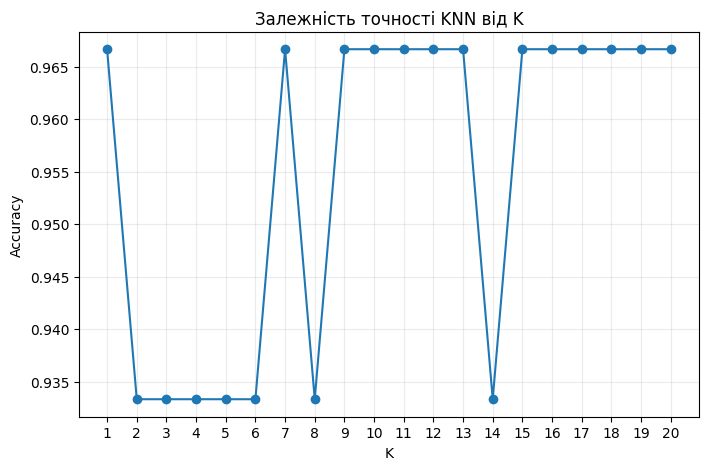

In [106]:
# 6. Графік залежності якості від K
plt.figure(figsize=(8, 5))
plt.plot(list(ks), accuracies, marker="o")
plt.xlabel("K")
plt.ylabel("Accuracy")
plt.title("Залежність точності KNN від K")
plt.xticks(list(ks))
plt.grid(True, alpha=0.25)
plt.show()

In [107]:
# 7. Вибір K
best_acc = max(accuracies)
best_ks = [k for k, a in zip(ks, accuracies) if a == best_acc]

# Серед значень з найкращою точністю беремо K=7:
# це непарне значення та дає меншу ймовірність нічиєї під час голосування сусідів.
chosen_k = 20 if 20 in best_ks else best_ks[0]

print("Найкраща точність на тестовій вибірці:", best_acc)
print("K зі найкращою точністю:", best_ks)
print("Обране K:", chosen_k)

Найкраща точність на тестовій вибірці: 0.9666666666666667
K зі найкращою точністю: [1, 7, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20]
Обране K: 20


In [108]:
# 8. Фінальна модель та оцінювання
final_model = KNeighborsClassifier(n_neighbors=chosen_k)
final_model.fit(X_train_scaled, y_train)

final_pred = final_model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, final_pred))
print("\nClassification report:")
print(classification_report(y_test, final_pred, zero_division=0))

Accuracy: 0.9666666666666667

Classification report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



In [109]:
# 9. Матриця помилок
cm = confusion_matrix(
    y_test,
    final_pred,
    labels=["Iris-setosa", "Iris-versicolor", "Iris-virginica"]
)

display(pd.DataFrame(
    cm,
    index=["Iris-setosa", "Iris-versicolor", "Iris-virginica"],
    columns=["Iris-setosa", "Iris-versicolor", "Iris-virginica"]
))

,Iris-setosa,Iris-versicolor,Iris-virginica
Iris-setosa,10,0,0
Iris-versicolor,0,9,1
Iris-virginica,0,0,10


In [110]:
# 10. Висновок
print(f"Для набору Iris обрано K={chosen_k}. "
      f"Точність класифікації на тестовій вибірці становить {best_acc*100:.2f}%.")


Для набору Iris обрано K=20. Точність класифікації на тестовій вибірці становить 96.67%.
